## Molecular Dynamics Simulation for 1 Particle

### ALGORITHM:

1. Define the box length L.
2. Set the particle's initial coordinates $(x, y)$ and velocity $(v_x, v_y)$.
3. Define the grid resolution scale ($\Delta x$) and CFL factor ($C$).
4. Compute the particle's speed:

$$v_{\text{max}} = \sqrt{v_x^2 + v_y^2}$$


5. Calculate the time step ($dt$) using the CFL:

$$\Delta t = 0.5 \cdot \left(\frac{\Delta x}{v_{\text{max}}}\right) \cdot C$$


6. Define the total time duration ($t_max$), initialize start time ($t$), and define the step factor ($steps\_per\_frame$).
7. Initialize history lists $x\_history$ and $y\_history$ with the starting coordinates to store the particle's trail.
8. Create a plot figure and axis fixed to limits $[0, L] \times [0, L]$ with an equal aspect ratio and background gridlines.
9. Initialize two Matplotlib artists:
* A line artist $trail\_line$ to draw the trajectory.
* A point artist $particle\_dot$ to display the particle's position.

10. Compute the total animation frames required to reach $t_max$:

$$\text{total\_frames} = \text{int}\left(\frac{t_{\text{max}}}{\Delta t \cdot \text{steps\_per\_frame}}\right)$$

11. Execute an inner loop running $steps\_per\_frame$ iterations.
12. Advance the coordinates:

$$x = x + v_x \Delta t$$


$$y = y + v_y \Delta t$$

13. Increment the time clock: $t = t + \Delta t$.
14. Evaluate the wall reflections:
* If $x < 0$: reflect $x$ to $-x$ and reverse $v_x$ to $-v_x$.
* Else if $x > L$: reflect $x$ to $2L - x$ and reverse $v_x$ to $-v_x$.
* If $y < 0$: reflect $y$ to $-y$ and reverse $v_y$ to $-v_y$.
* Else if $y > L$: reflect $y$ to $2L - y$ and reverse $v_y$ to $-v_y$.

15. Append the new $(x, y)$ coordinates to $x\_history$ and $y\_history$.
16. Update $trail\_line$ with the full $(x\_history, y\_history)$ lists.
17. Update $particle\_dot$ with the current coordinate pair $([x], [y])$.
18. Update $ax.set\_title$ with the plot label and tracker displaying current time $t$, position $(x, y)$, and velocity $(v_x, v_y)$.
19. Return the updated visual artists ($trail\_line$, $particle\_dot$).
20. Pass $update$, $frames=total\_frames$, $interval=20$, $blit=False$, and $repeat=False$ into $matplotlib.animation.FuncAnimation$.
21. Render and display the simulation window.

### CODE AND OUTPUT:

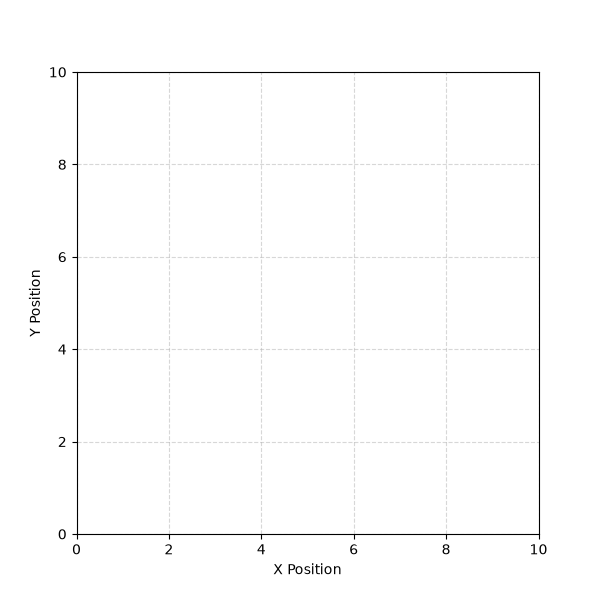

In [1]:
import matplotlib.animation as animation
import matplotlib.pyplot as plt
%matplotlib widget
import numpy as np

# PARAMETERS
L = 10.0  # Box dimensions (L x L)
x, y = 2.0, 3.0  # Initial positions
vx, vy = 4.0, 3.0  # Initial velocities
t_max = 20.0

dx = 0.1
C = 0.1  # CFL Factor
v_max = np.sqrt(vx**2 + vy**2)
dt = 0.5 * (dx / v_max) * C
steps_per_frame = 20
t = 0.0

x_history = [x]
y_history = [y]

# PLOT
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(0, L)
ax.set_ylim(0, L)
ax.set_aspect("equal")
ax.set_xlabel("X Position")
ax.set_ylabel("Y Position")
ax.grid(True, linestyle="--", alpha=0.5)

(trail_line,) = ax.plot([], [], color="royalblue", lw=1.5, alpha=0.7)
(particle_dot,) = ax.plot([], [], "ro", markersize=9)


# DYNAMICS
def update(frame):
    global x, y, vx, vy, t

    for i in range(steps_per_frame):
        x += vx * dt
        y += vy * dt
        t += dt

        # X-reflection
        if x < 0:
            x = -x
            vx = -vx
        elif x > L:
            x = 2 * L - x
            vx = -vx

        # Y-reflection
        if y < 0:
            y = -y
            vy = -vy
        elif y > L:
            y = 2 * L - y
            vy = -vy

        x_history.append(x)
        y_history.append(y)

    trail_line.set_data(x_history, y_history)
    particle_dot.set_data([x], [y])
    ax.set_title(
        f"Single Particle in 2D Box"
        f"\nTime: {t:.2f} s | Pos: ({x:.2f}, {y:.2f}) | Vel: ({vx:.1f}, {vy:.1f})"
    )
    return trail_line, particle_dot


total_frames = int(t_max / (dt * steps_per_frame))

ani = animation.FuncAnimation(
    fig,
    update,
    frames=total_frames,
    blit=False,
    repeat=False,
    interval=20,
)

plt.show()
